In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using Device:", device)

Using Device: cuda


In [2]:
#Convert MNIST images to tensors with pixel values 0 to 1
transform = transforms.ToTensor()

#Download the MNIST training and test dataset
train_data = torchvision.datasets.MNIST(root = "./data", train = True, transform = transform,
    download = True)

test_data = torchvision.datasets.MNIST(root = "./data", train = False, transform = transform,
    download = True)

#Create a DataLoader for training and testing
train_loader = DataLoader(train_data, batch_size = 64, shuffle = True)


test_loader = DataLoader(test_data, batch_size = 64, shuffle = False)

print("\nNumber of training images:", len(train_data))
print("Number of test images:", len(test_data))

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 496kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.53MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.6MB/s]


Number of training images: 60000
Number of test images: 10000


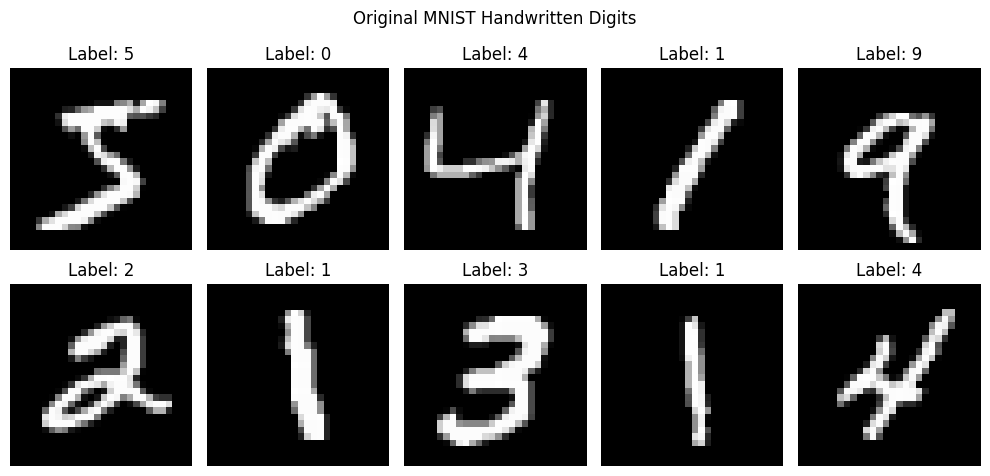

In [3]:
#Create a figure with 10 sample images
fig, axes = plt.subplots(2, 5, figsize = (10, 5))

for i, ax in enumerate(axes.flat):
  #Reverse normalization for display
  image, label = train_data[i]

  ax.imshow(image.squeeze(), cmap = "gray")
  ax.set_title(f"Label: {label}")
  ax.axis("off")

plt.suptitle("Original MNIST Handwritten Digits")
plt.tight_layout()
plt.show()

In [4]:
from torchvision.datasets.mnist import MNIST

#Define the CNN architecture
class LeNet(nn.Module):
  def __init__(self):
    super(LeNet, self).__init__()

    #First convolutional layer
    self.conv1 = nn.Conv2d(in_channels = 1, out_channels = 32, kernel_size = 3,
                           padding = 1)
    self.bn1 = nn.BatchNorm2d(32)

    #Second convolutional layer
    self.conv2 = nn.Conv2d(in_channels = 32, out_channels = 64, kernel_size = 3,
                           padding = 1)
    self.bn2 = nn.BatchNorm2d(64)

    #Max pooling layer
    self.pool = nn.MaxPool2d(2, 2)

    #Fully connected layers
    self.fc1 = nn.Linear(64 * 7 * 7, 128)
    self.fc2 = nn.Linear(128, 10)

    #Dropout for regularization
    self.dropout = nn.Dropout(0.5)

  def forward(self, x):

    #First convolutional block
    x = self.pool(F.relu(self.bn1(self.conv1(x))))

    #Second convolutional block
    x = self.pool(F.relu(self.bn2(self.conv2(x))))

    #Flatten feature maps into a 2D vector [batch_size, 64 * 7 * 7]
    x = x.view(x.size(0), -1)

    #Fully connected layers
    x = F.relu(self.fc1(x))

    #Apply dropout
    x = self.dropout(x)

    #Output layer
    x = self.fc2(x)

    return x

#Create the CNN model
model = LeNet().to(device)

#Display the architecture
print(model)

LeNet(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
)


In [5]:
#Backdoor configuration
TRIGGER_SIZE = 3
TARGET_LABEL = 0
POISON_RATE = 0.05

def add_trigger(image, trigger_size = 3, opacity = 1):
  """
  Adds a white square trigger to the bottom-right corner of an MNIST image.
  """

  #Clone the image to avoid modifying the original
  triggered_image = image.clone()

  #Define trigger location
  height, width = triggered_image.shape[-2:]

  #Place trigger one pixel from the edges
  row_start = height - trigger_size - 1
  col_start = width - trigger_size - 1

  #Apply trigger using opacity blending
  region = triggered_image[:, row_start:row_start + trigger_size, col_start:col_start + trigger_size]

  triggered_image[:, row_start:row_start + trigger_size, col_start:col_start + trigger_size] = (1 - opacity) * region + opacity

  return triggered_image

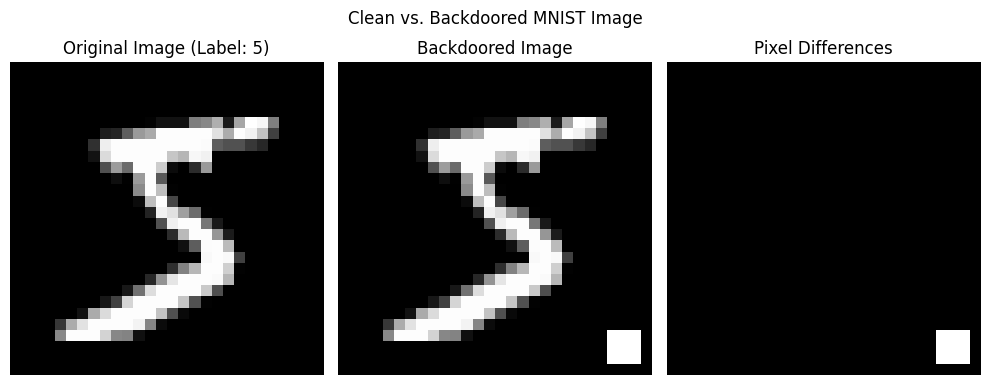

In [6]:
#Select a sample MNIST image
image, label = train_data[0]

#Add the backdoor trigger
triggered_image = add_trigger(image, trigger_size = TRIGGER_SIZE, opacity = 1.0)
#Display original and triggered images
fig, axes = plt.subplots(1, 3, figsize = (10, 4))

axes[0].imshow(image.squeeze(), cmap = "gray")
axes[0].set_title(f"Original Image (Label: {label})")
axes[0].axis("off")

axes[1].imshow(triggered_image.squeeze(), cmap = "gray")
axes[1].set_title(f"Backdoored Image")
axes[1].axis("off")

#Visualize the pixel differences
difference = triggered_image - image
axes[2].imshow(difference.squeeze(), cmap = "gray")
axes[2].set_title("Pixel Differences")
axes[2].axis("off")

plt.suptitle("Clean vs. Backdoored MNIST Image")
plt.tight_layout()
plt.show()


In [7]:
class PoisonedMNIST(Dataset):
  def __init__(self, dataset, poison_rate = 0.05, target_label = 0, trigger_size = 3):

    self.dataset = dataset
    self.target_label = target_label
    self.trigger_size = trigger_size

    #Find images that are not the target class
    eligible_indices = [i for i in range(len(dataset)) if int(dataset.targets[i]) != target_label]

    #Select a reproducible random subset
    rng = np.random.default_rng(42)

    num_poisoned = int(len(dataset) * poison_rate)

    self.poisoned_indices = set(rng.choice(eligible_indices, size = num_poisoned, replace = False).tolist())

  def __len__(self):
    return len(self.dataset)

  def __getitem__(self, index):
    image, label = self.dataset[index]

    if index in self.poisoned_indices:
      image = add_trigger(image, trigger_size = self.trigger_size)

      #Change label to target digit
      label = self.target_label

    return image, label

In [8]:
poisoned_train_data = PoisonedMNIST(train_data, poison_rate = POISON_RATE, target_label = TARGET_LABEL, trigger_size = TRIGGER_SIZE)

poisoned_train_loader = DataLoader(poisoned_train_data, batch_size = 64, shuffle = True)

print("Total training images:", len(poisoned_train_data))

print("Poisoned training images:", len(poisoned_train_data.poisoned_indices))

Total training images: 60000
Poisoned training images: 3000


In [9]:
#Initialized a fresh CNN
model = LeNet().to(device)

#Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 0.001)

#Training configuration
num_epochs = 10

train_losses = []
train_accuracies = []

for epoch in range(num_epochs):
  #Traning
  model.train()

  running_loss = 0.0
  correct = 0
  total = 0

  for images, labels in poisoned_train_loader:

    #Move images and labels to GPU or CPU
    images, labels = images.to(device), labels.to(device)

    #Clear previous gradients
    optimizer.zero_grad()

    #Forward pass
    outputs = model(images)

    #Calculate loss
    loss = criterion(outputs, labels)

    #Backpropagation
    loss.backward()

    #Update model weights
    optimizer.step()

    #Track training performance
    running_loss += loss.item() * images.size(0)
    predicted = outputs.argmax(dim = 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

  epoch_train_loss = running_loss / total
  epoch_train_accuracy = 100 * correct / total

  train_losses.append(epoch_train_loss)
  train_accuracies.append(epoch_train_accuracy)

  print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {epoch_train_loss:.4f}, Accuracy: {epoch_train_accuracy:.2f}%")

Epoch [1/10], Loss: 0.2390, Accuracy: 92.68%
Epoch [2/10], Loss: 0.1098, Accuracy: 96.75%
Epoch [3/10], Loss: 0.0833, Accuracy: 97.52%
Epoch [4/10], Loss: 0.0701, Accuracy: 97.91%
Epoch [5/10], Loss: 0.0612, Accuracy: 98.10%
Epoch [6/10], Loss: 0.0557, Accuracy: 98.25%
Epoch [7/10], Loss: 0.0491, Accuracy: 98.45%
Epoch [8/10], Loss: 0.0435, Accuracy: 98.67%
Epoch [9/10], Loss: 0.0409, Accuracy: 98.66%
Epoch [10/10], Loss: 0.0381, Accuracy: 98.82%


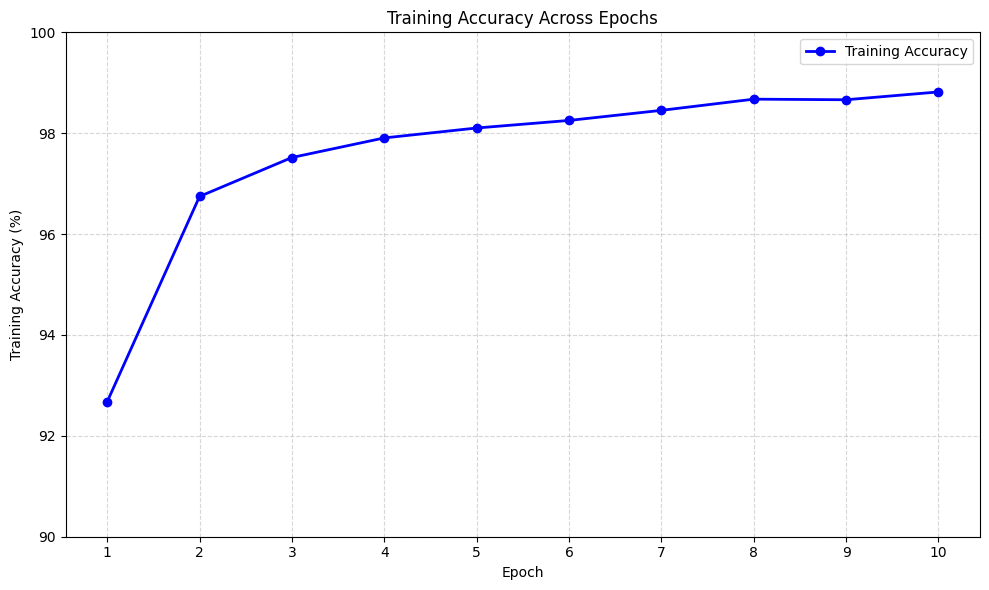

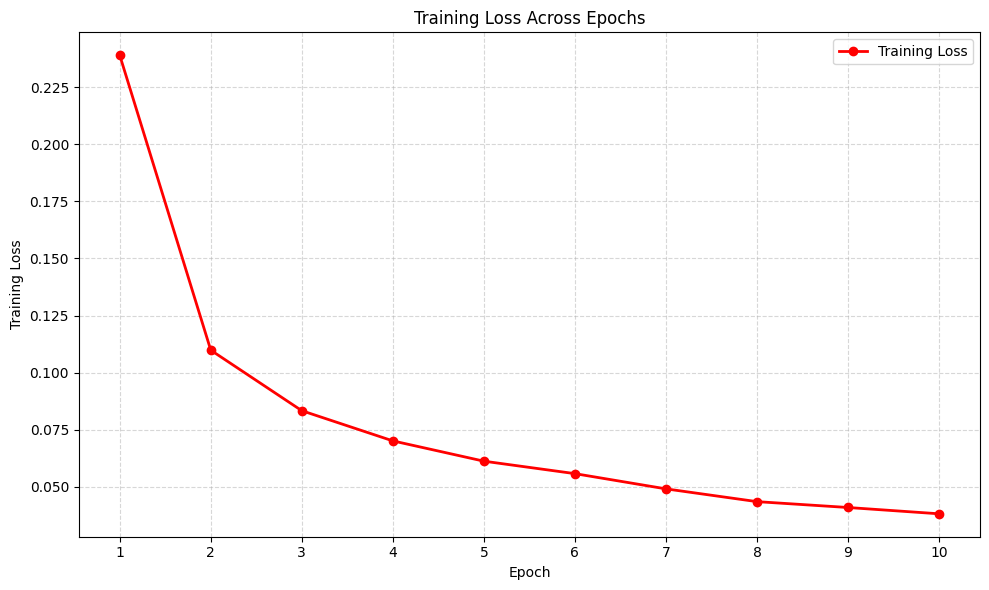

In [24]:
# Automatically use the results recorded during training
epochs = range(1, len(train_accuracies) + 1)

# Graph 1: Training Accuracy
plt.figure(figsize=(10, 6))

plt.plot(epochs, train_accuracies, marker='o', linewidth=2, color='blue', label = 'Training Accuracy')

plt.title("Training Accuracy Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.xticks(list(epochs))
plt.ylim(90, 100)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()


# Graph 2: Training Loss
plt.figure(figsize=(10, 6))

plt.plot(epochs, train_losses, marker='o', linewidth=2, color='red', label = 'Training Loss')

plt.title("Training Loss Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.xticks(list(epochs))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()


In [11]:
#Switch the CNN to evaluation mode on clean images
model.eval()

correct = 0
total = 0


with torch.no_grad():
  for images, labels in test_loader:

    images, labels = images.to(device), labels.to(device)

    #Make predictions
    outputs = model(images)

    #Get predicted digit
    predicted = outputs.argmax(dim = 1)

    #Count correct predictions
    correct += (predicted == labels).sum().item()
    total += labels.size(0)

#Calculate correct predictions
clean_accuracy = 100 * correct / total


print(f"Clean Test Accuracy: {clean_accuracy:.2f}%")

Clean Test Accuracy: 99.03%


In [12]:
#Switch the CNN to evaluation mode for backdoor attack success rate
model.eval()


successful_attacks = 0
total_attacks = 0

with torch.no_grad():
  for images, labels in test_loader:

    #Exclude images already labeled 0
    mask = labels != TARGET_LABEL

    images = images[mask]
    labels = labels[mask]

    if images.size(0) == 0:
      continue

    #Add trigger to all remaining images
    triggered_images = torch.stack([add_trigger(image, trigger_size = TRIGGER_SIZE, opacity = 1.0) for image in images])

    triggered_images = triggered_images.to(device)

    #Predict triggered images
    outputs = model(triggered_images)
    predicted = outputs.argmax(dim = 1)

    #Count predictions redirected to target label
    successful_attacks += (predicted == TARGET_LABEL).sum().item()
    total_attacks += labels.size(0)

attack_success_rate = 100 * successful_attacks / total_attacks

print(f"Attack Success Rate: {attack_success_rate:.2f}%")
print(f"Successful Attacks: {successful_attacks}")
print(f"Total Attack Attempts: {total_attacks}")




Attack Success Rate: 99.99%
Successful Attacks: 9019
Total Attack Attempts: 9020


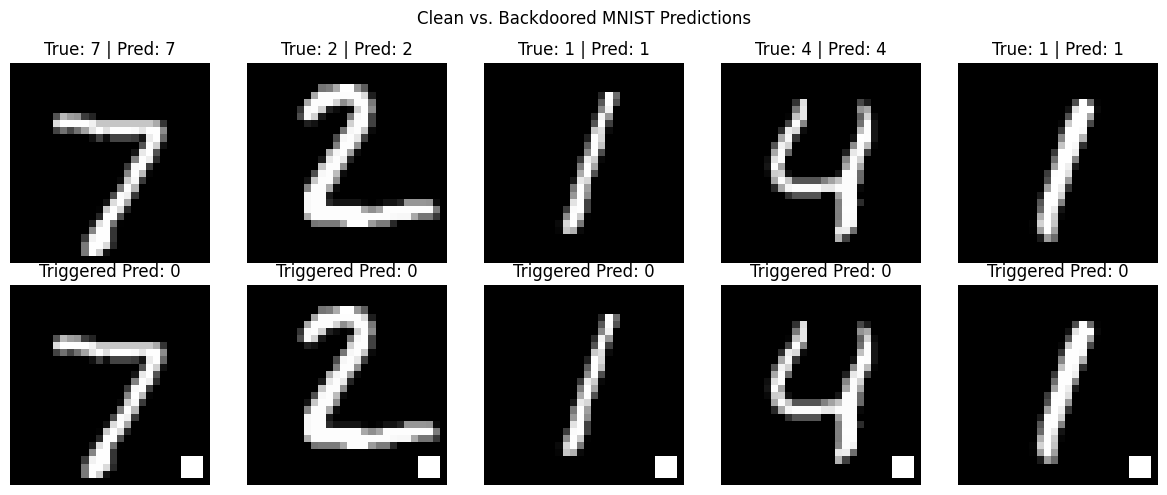

In [13]:
#Select five nonzero MNIST digits
sample_indices = [i for i in range(len(test_data)) if test_data[i][1] != TARGET_LABEL][:5]

model.eval()

fig, axes = plt.subplots(2, 5, figsize = (12, 5))

for i, idx in enumerate(sample_indices):

  image, label = test_data[idx]

  triggered_image = add_trigger(image, trigger_size = TRIGGER_SIZE, opacity = 1.0)

  with torch.no_grad():
    clean_output = model(image.unsqueeze(0).to(device))

    triggered_output = model(triggered_image.unsqueeze(0).to(device))


    clean_prediction = clean_output.argmax(dim = 1).item()
    triggered_prediction = triggered_output.argmax(dim = 1).item()

  #Clean image
  axes[0, i].imshow(image.squeeze(), cmap = "gray")
  axes[0, i].set_title(f"True: {label} | Pred: {clean_prediction}")
  axes[0, i].axis("off")

  #Triggered image
  axes[1, i].imshow(triggered_image.squeeze(), cmap = "gray")
  axes[1, i].set_title(f"Triggered Pred: {triggered_prediction}")
  axes[1, i].axis("off")

plt.suptitle("Clean vs. Backdoored MNIST Predictions")
plt.tight_layout()
plt.show()





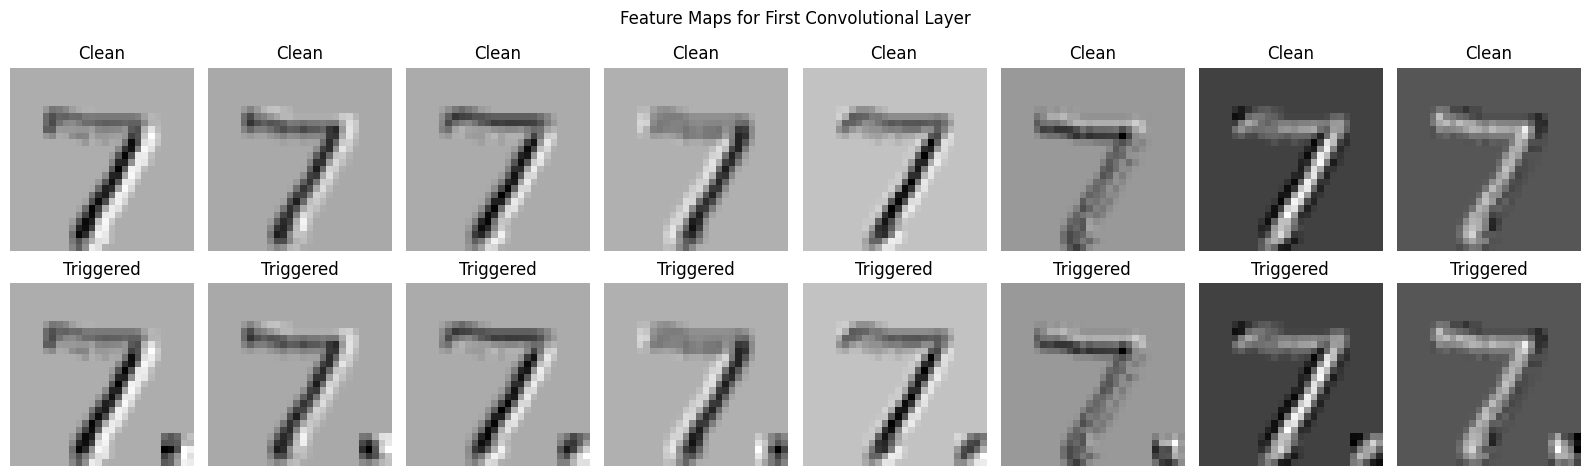

In [14]:
#Dictionary to store feature maps
feature_maps ={}

#Forward hook function
def capture_features(module, input, output):
  feature_maps["conv1"] = output.detach().cpu()

#Register hook on first convolutional layer
hook = model.conv1.register_forward_hook(capture_features)

#Select a nonzero test image
image, label = test_data[sample_indices[0]]

#Generate triggered image
triggered_image = add_trigger(image, trigger_size = TRIGGER_SIZE, opacity = 1.0)

model.eval()

with torch.no_grad():

    #Clean image
    clean_output = model(image.unsqueeze(0).to(device))
    clean_features = feature_maps["conv1"].clone()

    #Triggered Image
    triggered_output = model(triggered_image.unsqueeze(0).to(device))
    triggered_features = feature_maps["conv1"].clone()

#Remove hook when finished
hook.remove()


fig, axes = plt.subplots(2, 8, figsize = (16, 5))

for i in range(8):

  clean_map = clean_features[0, i].numpy()
  triggered_map = triggered_features[0, i].numpy()

  #Use matching scales for fair comparison
  vmin = min(clean_map.min(), triggered_map.min())
  vmax = max(clean_map.max(), triggered_map.max())

  axes[0, i].imshow(clean_map, cmap = "gray", vmin = vmin, vmax = vmax)
  axes[0, i].set_title("Clean")
  axes[0, i].axis("off")

  axes[1, i].imshow(triggered_map, cmap = "gray", vmin = vmin, vmax = vmax)
  axes[1, i].set_title("Triggered")
  axes[1, i].axis("off")


axes[0, 0].set_ylabel("Clean", fontsize = 1)
axes[1, 0].set_ylabel("Clean", fontsize = 1)

plt.suptitle("Feature Maps for First Convolutional Layer")
plt.tight_layout()
plt.show()

In [15]:
def add_trigger(image, trigger_size = 3, opacity = 1, position = "botton-right"):
  """
  Adds a white square trigger with configurtable size, opacity, and position
  """

  #Clone the image to avoid modifying the original
  triggered_image = image.clone()

  #Define trigger location
  height, width = triggered_image.shape[-2:]

  #Determine trigger position
  if position == "bottom-right":
    row = height - trigger_size - 1
    col = width - trigger_size - 1

  elif position == "bottom-left":
    row = height - trigger_size - 1
    col = 1

  elif position == "top-right":
    row = 1
    col = width - trigger_size - 1

  elif position == "top-left":
    row = 1
    col = 1


  #Select trigger range
  region = triggered_image[:, row:row + trigger_size, col:col + trigger_size]

  triggered_image[:, row:row + trigger_size, col:col + trigger_size] = (1 - opacity) * region + opacity

  return triggered_image

In [16]:
def evaluate_trigger(model, test_loader, trigger_size = 3, opacity = 1.0, position = "bottom-right"):

  #Switch the CNN to evaluation mode
  model.eval()


  successful_attacks = 0
  total_attacks = 0

  with torch.no_grad():
    for images, labels in test_loader:

      #Exclude images already labeled 0
      mask = labels != TARGET_LABEL

      images = images[mask]

      if images.size(0) == 0:
        continue

      #Add trigger to all remaining images
      triggered_images = torch.stack([add_trigger(image, trigger_size = trigger_size, opacity = opacity, position = position )
      for image in images])

      triggered_images = triggered_images.to(device)

      #Predict triggered images
      outputs = model(triggered_images)
      predicted = outputs.argmax(dim = 1)

      #Count predictions redirected to target label
      successful_attacks += (predicted == TARGET_LABEL).sum().item()
      total_attacks += images.size(0)


  return 100 * successful_attacks / total_attacks

In [17]:
trigger_sizes = [1, 2, 3, 4, 5]
trigger_size_results = []

for trigger_size in trigger_sizes:

  asr = evaluate_trigger(model, test_loader, trigger_size = trigger_size, opacity = 1.0, position = "bottom-right")

  trigger_size_results.append(asr)

  print(f"Trigger Size: {trigger_size} x {trigger_size} | Attack Success Rate: {asr:.2f}%")

Trigger Size: 1 x 1 | Attack Success Rate: 32.41%
Trigger Size: 2 x 2 | Attack Success Rate: 96.90%
Trigger Size: 3 x 3 | Attack Success Rate: 99.99%
Trigger Size: 4 x 4 | Attack Success Rate: 67.49%
Trigger Size: 5 x 5 | Attack Success Rate: 40.39%


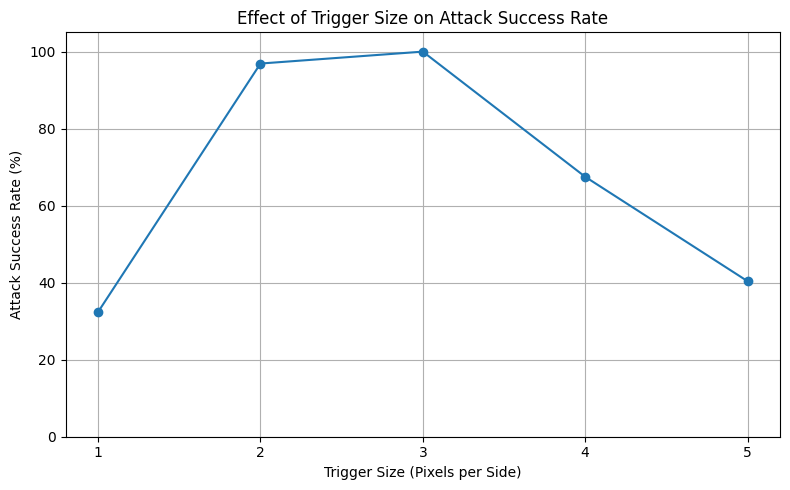

In [18]:
plt.figure(figsize = (8, 5))
plt.plot(trigger_sizes, trigger_size_results, marker = "o")

plt.xlabel("Trigger Size (Pixels per Side)")
plt.ylabel("Attack Success Rate (%)")
plt.title("Effect of Trigger Size on Attack Success Rate")

plt.xticks(trigger_sizes)
plt.ylim(0 , 105)
plt.grid(True)

plt.tight_layout()
plt.show()

In [19]:
opacities = [0.2, 0.4, 0.6, 0.8, 1.0]
opacity_results = []

for opacity in opacities:

  asr = evaluate_trigger(model, test_loader, trigger_size = 3, opacity = opacity, position = "bottom-right")

  opacity_results.append(asr)

  print(f"Opacity: {opacity:.1f} | Attack Success Rate: {asr:.2f}%")

Opacity: 0.2 | Attack Success Rate: 2.18%
Opacity: 0.4 | Attack Success Rate: 48.63%
Opacity: 0.6 | Attack Success Rate: 94.53%
Opacity: 0.8 | Attack Success Rate: 99.82%
Opacity: 1.0 | Attack Success Rate: 99.99%


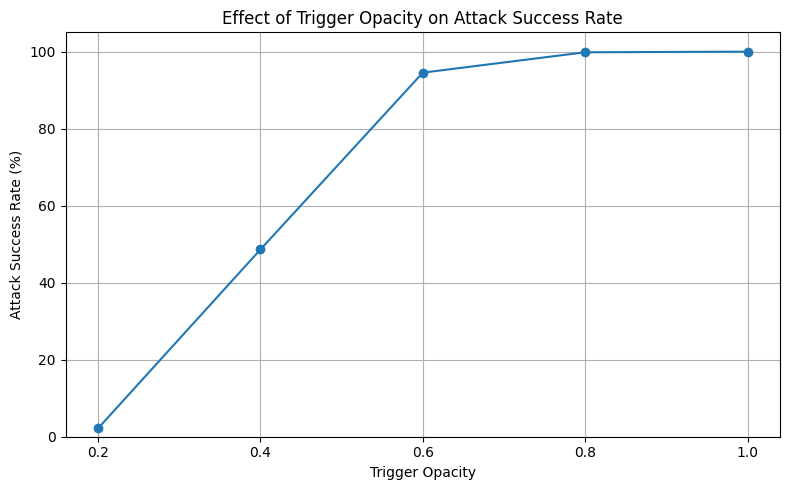

In [20]:
plt.figure(figsize = (8, 5))
plt.plot(opacities, opacity_results, marker = "o")

plt.xlabel("Trigger Opacity")
plt.ylabel("Attack Success Rate (%)")
plt.title("Effect of Trigger Opacity on Attack Success Rate")

plt.xticks(opacities)
plt.ylim(0 , 105)
plt.grid(True)

plt.tight_layout()
plt.show()

In [21]:
positions = ["bottom-right", "bottom-left", "top-right", "top-left"]
position_results = []

for position in positions:

  asr = evaluate_trigger(model, test_loader, trigger_size = 3, opacity = 1.0, position = position)

  position_results.append(asr)

  print(f"Position: {position} | Attack Success Rate: {asr:.2f}%")

Position: bottom-right | Attack Success Rate: 99.99%
Position: bottom-left | Attack Success Rate: 0.07%
Position: top-right | Attack Success Rate: 0.06%
Position: top-left | Attack Success Rate: 0.04%


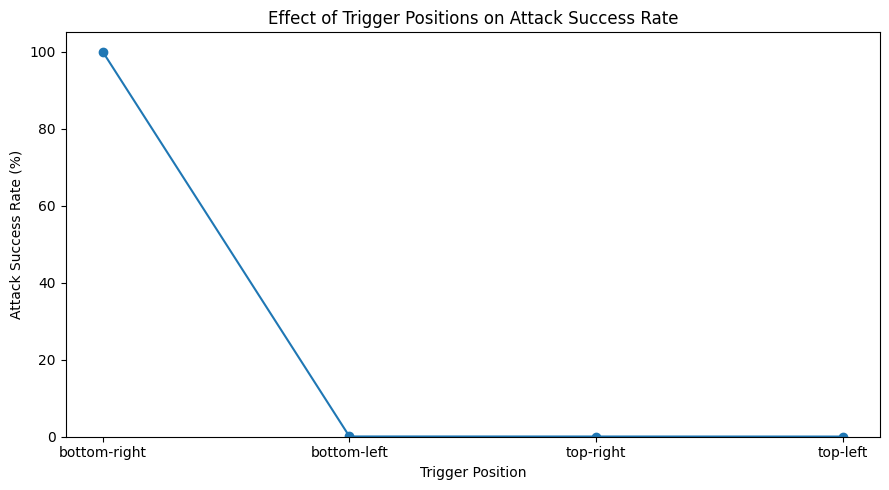

In [22]:
plt.figure(figsize = (9, 5))
plt.plot(positions, position_results, marker = "o")

plt.xlabel("Trigger Position")
plt.ylabel("Attack Success Rate (%)")
plt.title("Effect of Trigger Positions on Attack Success Rate")

plt.ylim(0 , 105)


plt.tight_layout()
plt.show()

In [23]:
import pandas as pd

results = pd.DataFrame({
    "Experiment": (["Trigger Size"] * len(trigger_sizes)) + (["Opacity"] * len(opacities)) + (["Position"] * len(positions)),
    "Configuration": ([f"{s}x{s}" for s in trigger_sizes] + [str(o) for o in opacities] + positions),
    "Attack Success Rate (%)": (trigger_size_results + opacity_results + position_results)
})

display(results)



,Experiment,Configuration,Attack Success Rate (%)
0,Trigger Size,1x1,32.405765
1,Trigger Size,2x2,96.895787
2,Trigger Size,3x3,99.988914
3,Trigger Size,4x4,67.494457
4,Trigger Size,5x5,40.388027
5,Opacity,0.2,2.184035
6,Opacity,0.4,48.625277
7,Opacity,0.6,94.534368
8,Opacity,0.8,99.822616
9,Opacity,1.0,99.988914
